In [12]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
import pandas as pd
import numpy as np
import json
import random
from xgboost import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from imblearn.under_sampling import RandomUnderSampler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from src.modelos import MLP_regresion, MLP_clasificacion
from src.utils import df_features_to_numpy, df_target_to_numpy, run_experiment_pytorch_clasificacion, run_experiment_pytorch_regresion, permutation_importance_pytorch
from src.splitting import split_estratificado_autor
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_confusion_matrix, plot_learning_curves_xgboost_regression, plot_learning_curves_xgboost_classification, plot_feature_importance_xgb, plot_learning_curves_randomforest_regression, plot_learning_curves_randomforest_classification, plot_feature_importance_rf, plot_feature_importance_pytorch

# Cargo el dataset ya procesado

In [14]:
#LEO TEST
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_test:
    chunk_list.append(chunk)
df_test = pd.concat(chunk_list, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)
df_val = pd.concat(chunk_list, ignore_index=True)

#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)
df_train = pd.concat(chunk_list, ignore_index=True)

## Preparacion de los datos

In [16]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'AUDIO', 'COMIC', 'EBOOK', 'HARDCOVER', 'OTHER', 'PAPERBACK', "language_code_ang", "language_code_en", "language_code_en-CA", "language_code_en-GB", "language_code_en-US", "language_code_eng", "language_code_enm", "language_code_gem", "language_code_sco", "cantidad_generos"] + generos #'UNKNOWN' la saco por el one hot en regresion

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

### Variables que necesito para hacer grid search
Creo un subset estratificado (por estrellas) de 50mil muestras. Este subset nos sirve para hacer un grid search manteniendo las distribuciones pero sin que tome mucho tiempo ni capacidad de computo. 

In [17]:
#variables que necesito para grid search, tanto para random forest como para xgboost
X_sub, _, y_sub_regresion, _, y_sub_clasificacion, _ = train_test_split(X_train_scaled, y_train_regresion, y_train_clasificacion, train_size=100000, stratify=y_train_clasificacion, random_state=42)

parametros_grid_search_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

parametros_grid_search_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[128, 64], [256, 128], [256, 128, 64]],
    "dropout": [0.0, 0.2, 0.4],
    "lr": [0.01, 0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

### Preparo los datos que voy a usar en los modelos cuando quiera usar tecnicas de rebalanceo

In [21]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {4: 225000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_scaled, y_train_clasificacion) 

#Hago undersampling para el subset usado en grid search
cant_datos_deseada_sub = {4: 50000} 
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub, y_sub_clasificacion) 

El valor optimo encontrado en ModeloBase para la cantidad de datos deseada de la clase 4 post undersampling es 225000, lo que corresponde aproximadamente al 50% del dataset de train. <br>
Entonces, para la cantidad de datos deseada de la clase 4 para el subset de grid search, tomo como valor el 50% de los datos de X_sub (subset de train). Para el subset elijo 100000 muestras, por lo que la cantidad de datos deseada de la clase 4 post undersampling va a ser 50000. 

## Random Forest con features basicas - Regresion

Grid Search: tomo una muestra de 100 mil datos para encontrar los mejores hiperparametros, una vez encontrados estos valores reentreno con todos los datos

In [22]:
RandomForestGridSearchRegresion = RandomForestRegressor(random_state=42)
grid = GridSearchCV(estimator = RandomForestGridSearchRegresion, param_grid = parametros_grid_search_rf, cv = 3, scoring="r2", n_jobs=-1, verbose=2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Mejor R² CV: 0.2025866763971781


In [23]:
modeloRandomForestRegresion = RandomForestRegressor(**mejores_parametros, random_state = 42)
modeloRandomForestRegresion.fit(X_train_scaled, y_train_regresion)

y_pred_train_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_train_scaled)
y_pred_val_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloRandomForestRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloRandomForestRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.094731    0.111398
RMSE  0.307785    0.333763
MAE   0.235822    0.256908
R²    0.330143    0.214624


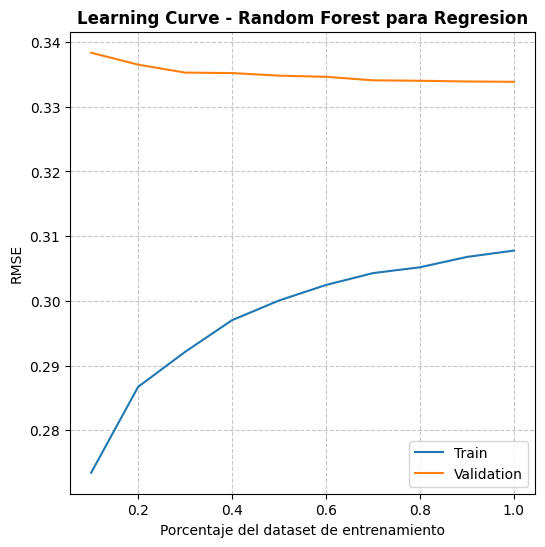

In [24]:
plot_learning_curves_randomforest_regression(X_train, y_train_regresion, X_val, y_val_regresion, **mejores_parametros)

Analizamos la feature importance:

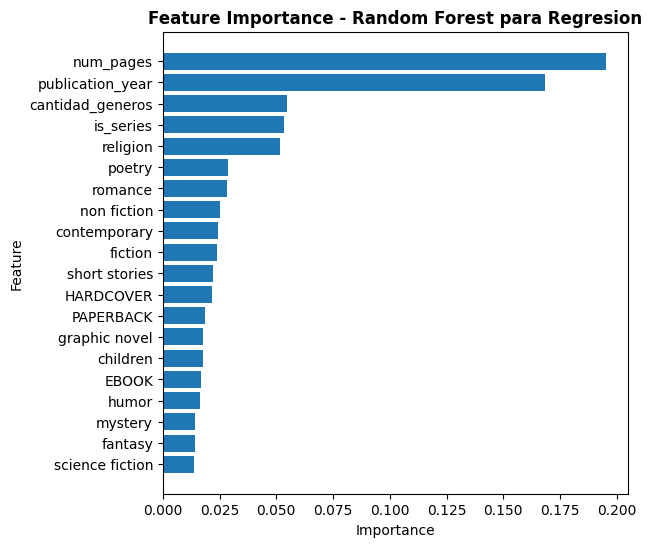

In [25]:
importancias_coef_rf_reg = pd.DataFrame({"feature": features, "importance": modeloRandomForestRegresion.feature_importances_})
importancias_coef_rf_reg = importancias_coef_rf_reg.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_reg, "para Regresion")

## Random Forest con features basicas - Clasificacion

Uso rebalanceo undersampling + cost re weight, con los pesos y cantidades optimos encontrados en Modelo Base.

In [26]:
pesos = {1:8, 2:2, 3:2, 4:1, 5:3}
RandomForestGridSearchClasificacion = RandomForestClassifier(random_state = 42, class_weight = pesos)

#uso las mismas opciones de hiperparametros q use en regresion, y los mismos indices para obtener los subconjuntos
grid = GridSearchCV(estimator = RandomForestGridSearchClasificacion, param_grid = parametros_grid_search_rf, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
grid.fit(X_sub_undersampling, y_sub_clasificacion_undersampling)

mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor F1 CV: {grid.best_score_}")

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
Mejor F1 CV: 0.2917394344719937


              Train  Validation
Accuracy   0.758574    0.765566
Precision  0.371964    0.297002
Recall     0.329642    0.290699
F1         0.345534    0.293372


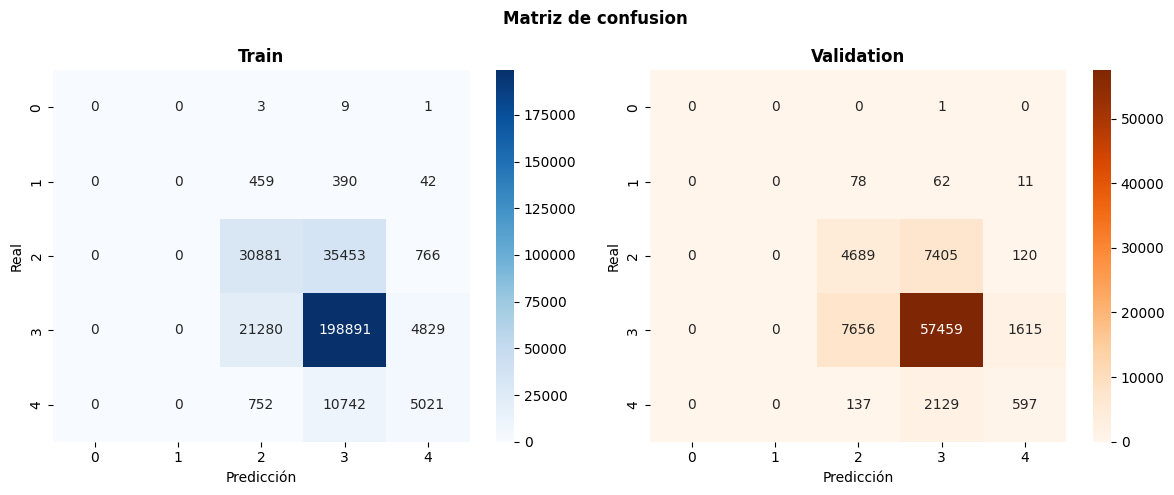

In [27]:
modeloRandomForestClasificacion = RandomForestClassifier(**mejores_parametros, random_state = 42, class_weight = pesos)
modeloRandomForestClasificacion.fit(X_train_undersampling, y_train_undersampling)

y_pred_train_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_train_undersampling))
y_pred_val_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_val_scaled))

metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloRandomForestClasificacion, y_train_undersampling)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloRandomForestClasificacion, y_val_clasificacion)
tabla_metricas_rf_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_rf_clasificacion)

cm_train = confusion_matrix(y_train_undersampling, y_pred_train_modeloRandomForestClasificacion)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloRandomForestClasificacion)
plot_confusion_matrix(cm_train, cm_val)

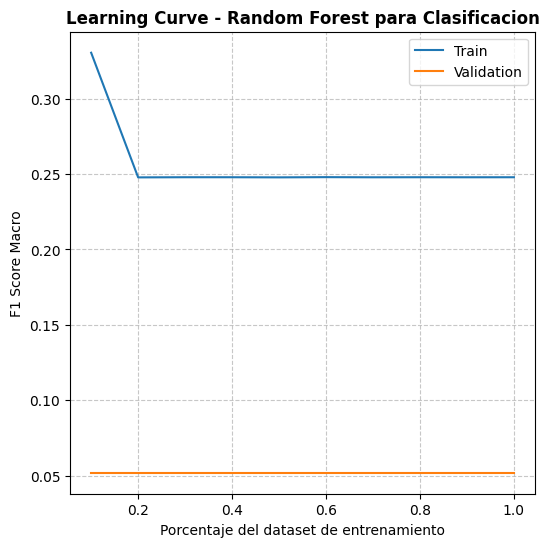

In [28]:
plot_learning_curves_randomforest_classification(X_sub_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion, pesos = pesos, **mejores_parametros)

Analizamos la feature importance:

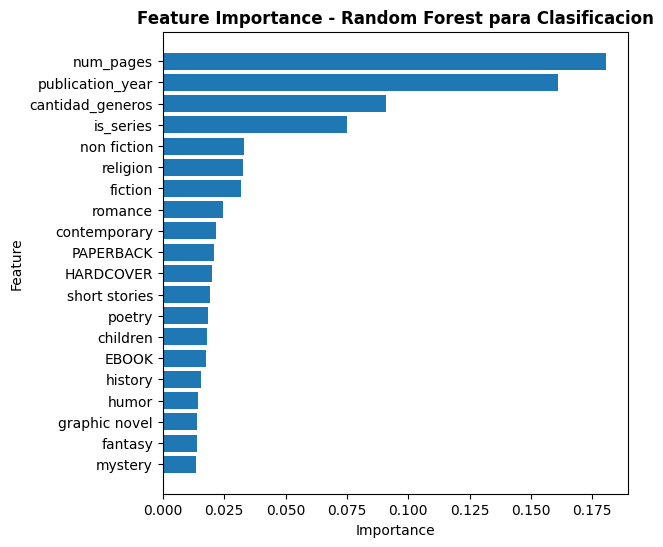

In [29]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": features, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificacion")

## XGBoost con features basicas - Regresion

Empiezo con grid search para buscar los mejores hiperparametros

In [30]:
XGBoostGridSearchRegresion = XGBRegressor(random_state = 42)
grid = GridSearchCV(estimator = XGBoostGridSearchRegresion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "r2", n_jobs = -1, verbose = 2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Mejor R² CV: 0.21235470875572413


In [31]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(**mejores_parametros, objective = "reg:squarederror", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_train_scaled, y_train_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_scaled)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.107125    0.109674
RMSE  0.327299    0.331170
MAE   0.251485    0.254547
R²    0.242508    0.226777


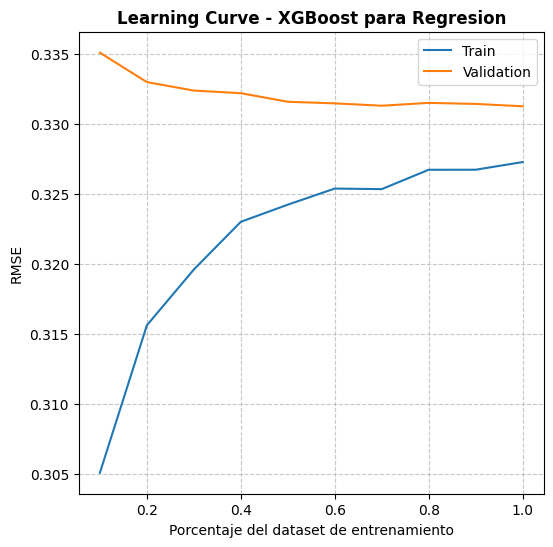

In [32]:
plot_learning_curves_xgboost_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, **mejores_parametros)

Analizamos las feature importance:

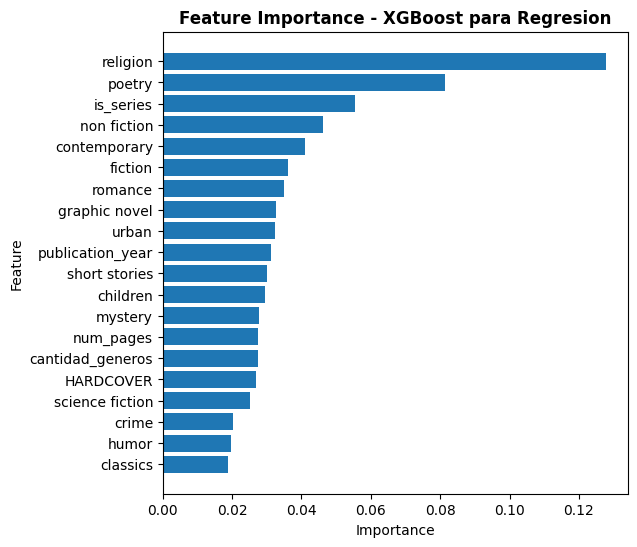

In [33]:
importancias_coef_xgb_reg = pd.DataFrame({"feature": features, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresion")

## XGBoost con features basicas - Clasificacion

Hago un poco de rebalanceo antes de empezar, utilizo X_sub_undersampling (X_train con menos datos de la clase mayoritaria 4). <br>
Aparte, XGBoost solo trabaja con clases empezando desde 0, (aunque nuestras estrellas vayan de 1 a 5). Para poder entrenar con este modelo, transformo temporalmente el target restando 1. 

In [38]:
#transformaciones temporales
y_sub_temp = y_sub_clasificacion_undersampling - 1
y_train_temp = y_train_undersampling - 1
y_val_temp = y_val_clasificacion - 1
pesos = {0:8, 1:2, 2:2, 3:1, 4:3} #mismos pesos que ModeloBase, pero con las clases yendo temporalmente de 0 a 4

In [37]:
pesos_transformados_sub = np.array([pesos[y] for y in y_sub_temp])
XGBoostGridSearchClasificacion = XGBClassifier(objective = "multi:softmax", num_class = 5, random_state = 42) 

#uso los mismos indices para obtener los subconjuntos
grid = GridSearchCV(estimator = XGBoostGridSearchClasificacion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
grid.fit(X_sub_undersampling, y_sub_temp, sample_weight = pesos_transformados_sub)

mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor F1 CV: {grid.best_score_}")

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Mejor F1 CV: 0.3244330698653975


              Train  Validation
Accuracy   0.709708    0.733660
Precision  0.690738    0.287895
Recall     0.524456    0.310252
F1         0.507190    0.296567


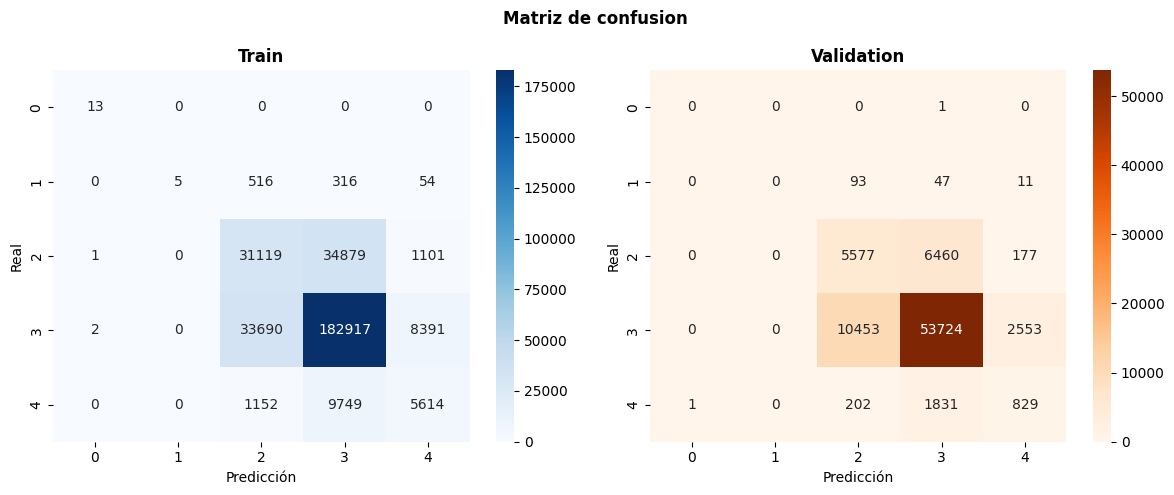

In [39]:
pesos_transformados_train = np.array([pesos[y] for y in y_train_temp])
modeloXGBoostClasificacion = XGBClassifier(**mejores_parametros, objective = "multi:softmax", num_class = 5, random_state = 42) 
modeloXGBoostClasificacion.fit(X_train_undersampling, y_train_temp, sample_weight = pesos_transformados_train) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train = (modeloXGBoostClasificacion.predict(X_train_undersampling))
y_pred_val = (modeloXGBoostClasificacion.predict(X_val_scaled))
#volvemos a las clases originales sumando 1
y_pred_train_modeloXGBoostClasificacion = y_pred_train + 1
y_pred_val_modeloXGBoostClasificacion = y_pred_val + 1

#calculo las metricas usando las clases originales entre 1 y 5
metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloXGBoostClasificacion, y_train_undersampling)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloXGBoostClasificacion, y_val_clasificacion)
tabla_metricas_xgboost_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_xgboost_clasificacion)

cm_train = confusion_matrix(y_train_undersampling, y_pred_train_modeloXGBoostClasificacion)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloXGBoostClasificacion)
plot_confusion_matrix(cm_train, cm_val)

In [40]:
plot_learning_curves_xgboost_classification(X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion, pesos = pesos_transformados_train,**mejores_parametros)

ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1 2 3], got [2 3 4 5]

Analizamos las feature importance:

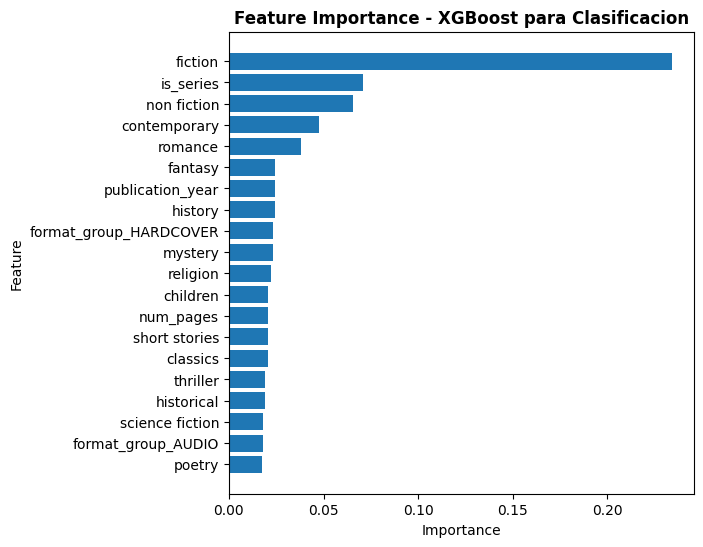

In [ ]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": features, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificacion")

## Red neuronal con features basicas - Regresion

In [ ]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"

Grid search

In [ ]:
from src.utils import run_grid_search_pytorch_regresion

mejor_r2 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                modelo = MLP_regresion(input_size = X_sub.shape[1], hidden_layers=capas_ocultas, activation=activacion, dropout=dropout).to(device)
                r2 = run_grid_search_pytorch_regresion(modelo=modelo, learning_rate = lr, model_name="MLP Regresion", X_train=X_sub, y_train=y_sub_regresion, X_val=X_val_scaled, y_val=y_val_regresion, device=device, epochs=30)
                if r2 > mejor_r2:
                    mejor_r2 = r2
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

PyTorch: 100%|██████████| 30/30 [01:00<00:00,  2.01s/epoca, epoch=30]


Mejores parametros: {'capas_ocultas': [128, 64], 'dropout': 0.2, 'lr': 0.01, 'activacion': <class 'torch.nn.modules.activation.ReLU'>}


PyTorch: 100%|██████████| 100/100 [16:55<00:00, 10.15s/epoca, epoch=100]


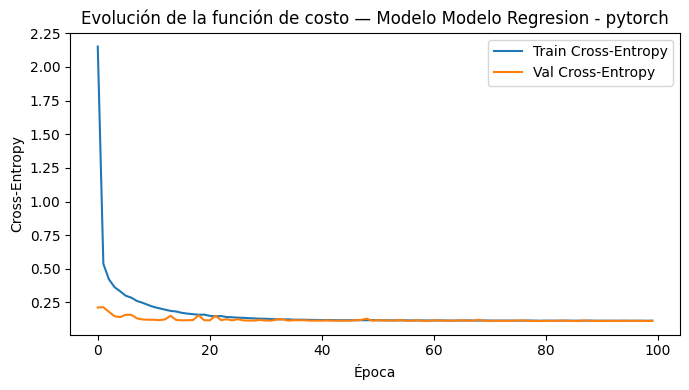

         Train  Validation
MSE   0.111451    0.112449
RMSE  0.333842    0.335334
MAE   0.255599    0.256873
R²    0.211919    0.207212


In [ ]:
#TODO: cambiar hidden_layers por capas ocultas y activation por activacion
modelo_regresion = MLP_regresion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_regresion(modelo_regresion, "Modelo Regresion", X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, device, learning_rate = mejores_parametros["lr"])
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

Las redes neuronales con pytorch no tienen un atributo para acceder a la feature importance, a diferencia de XGBoost o Random Forest. Para simular esto, se agarra por separado cada feature y se la mezcla (de esta manera se descorrelaciona la salida del modelo con esta feature). Despues, se predice con esa nueva feature y se evalua la diferencia con el X original. A mayor diferencia mayor impacto tiene la feature. 

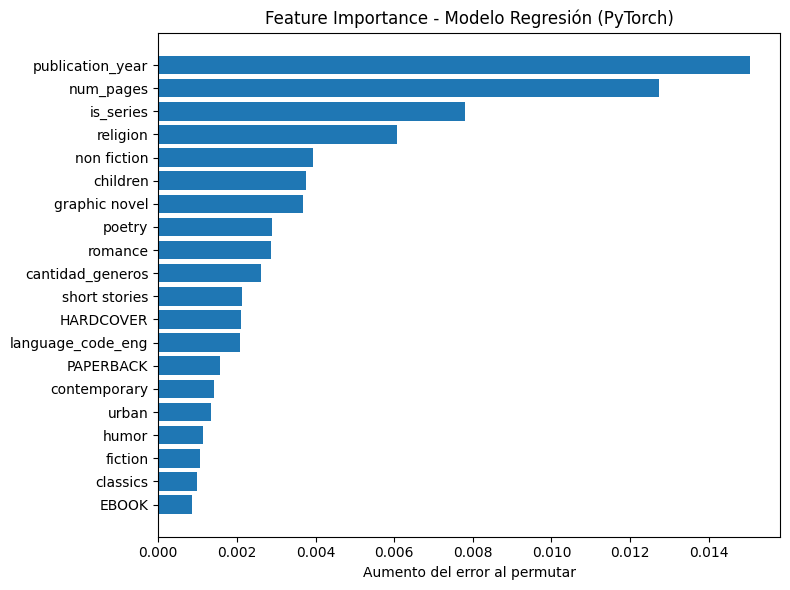

In [ ]:
feature_importance_regresion = permutation_importance_pytorch(modelo_regresion, X_val_scaled, y_val_regresion, features, device,metric_fn=mean_squared_error, higher_is_better=False, n_repeats=10)
plot_feature_importance_pytorch(feature_importance_regresion, top_n=20, title="Feature Importance - Modelo Regresión (PyTorch)")

## Red neuronal con features basicas - Clasificacion

In [ ]:
from src.utils import run_grid_search_pytorch_clasificacion

mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout={dropout}, lr={lr}, activacion={activacion.__name__}")
                modelo = MLP_clasificacion(input_size=X_sub.shape[1], hidden_layers=capas_ocultas, n_classes=5, activation=activacion, dropout=dropout).to(device)

                f1 = run_grid_search_pytorch_clasificacion(modelo=modelo, learning_rate=lr, model_name="MLP Clasificacion", X_train=X_sub, y_train=y_sub_clasificacion, X_val=X_val_scaled, y_val=y_val_clasificacion, device=device, epochs=30)

                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

c:\Users\czava\Documents\IA_tercer_anio\ML\TPF_ML\src\utils.py:107: RuntimeWarning: divide by zero encountered in divide
  weights = np.sqrt(counts.sum() / counts)
c:\Users\czava\Documents\IA_tercer_anio\ML\TPF_ML\src\utils.py:108: RuntimeWarning: invalid value encountered in divide
  weights = weights / weights.mean()


Probando: [128, 64], dropout=0.0, lr=0.01, activacion=ReLU


PyTorch:   0%|          | 0/30 [00:00<?, ?epoca/s]


RuntimeError: weight tensor should be defined either for all 5 classes or no classes but got weight tensor of shape: [6]

In [ ]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"])
print(tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"]))

NameError: name 'mejores_parametros' is not defined

In [ ]:
feature_importance_regresion = permutation_importance_pytorch(modelo_regresion, X_val_scaled, y_val_regresion, features, device, metric_fn=accuracy_score, higher_is_better=X_train_undersampling, n_repeats=10)
plot_feature_importance_pytorch(feature_importance_regresion, top_n=20, title="Feature Importance - Modelo Clasificacion (PyTorch)")